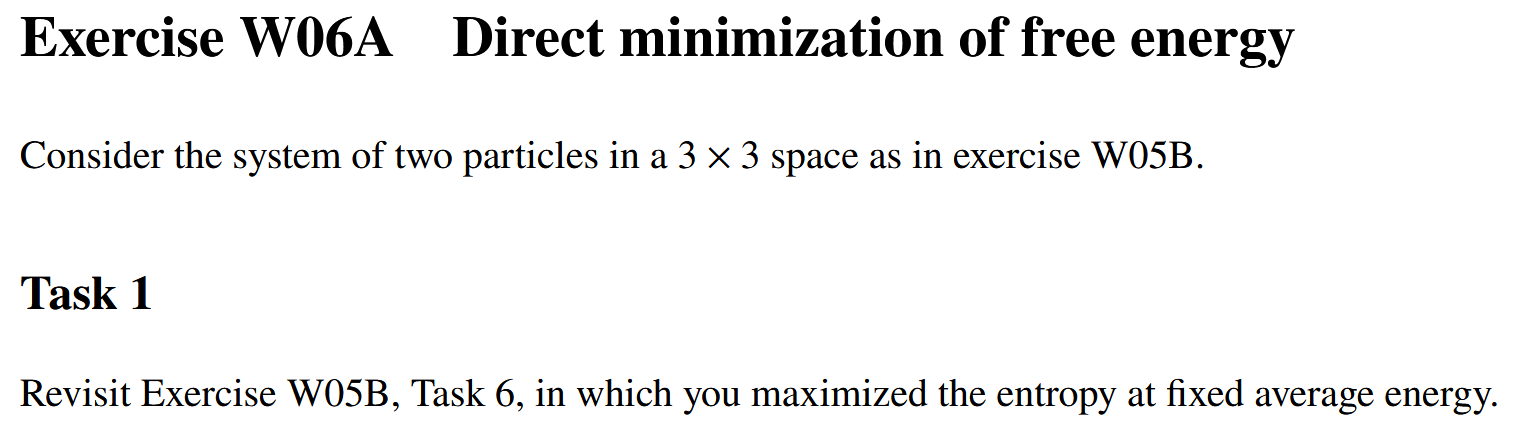
## I didnt do this exercise yet $\uparrow$
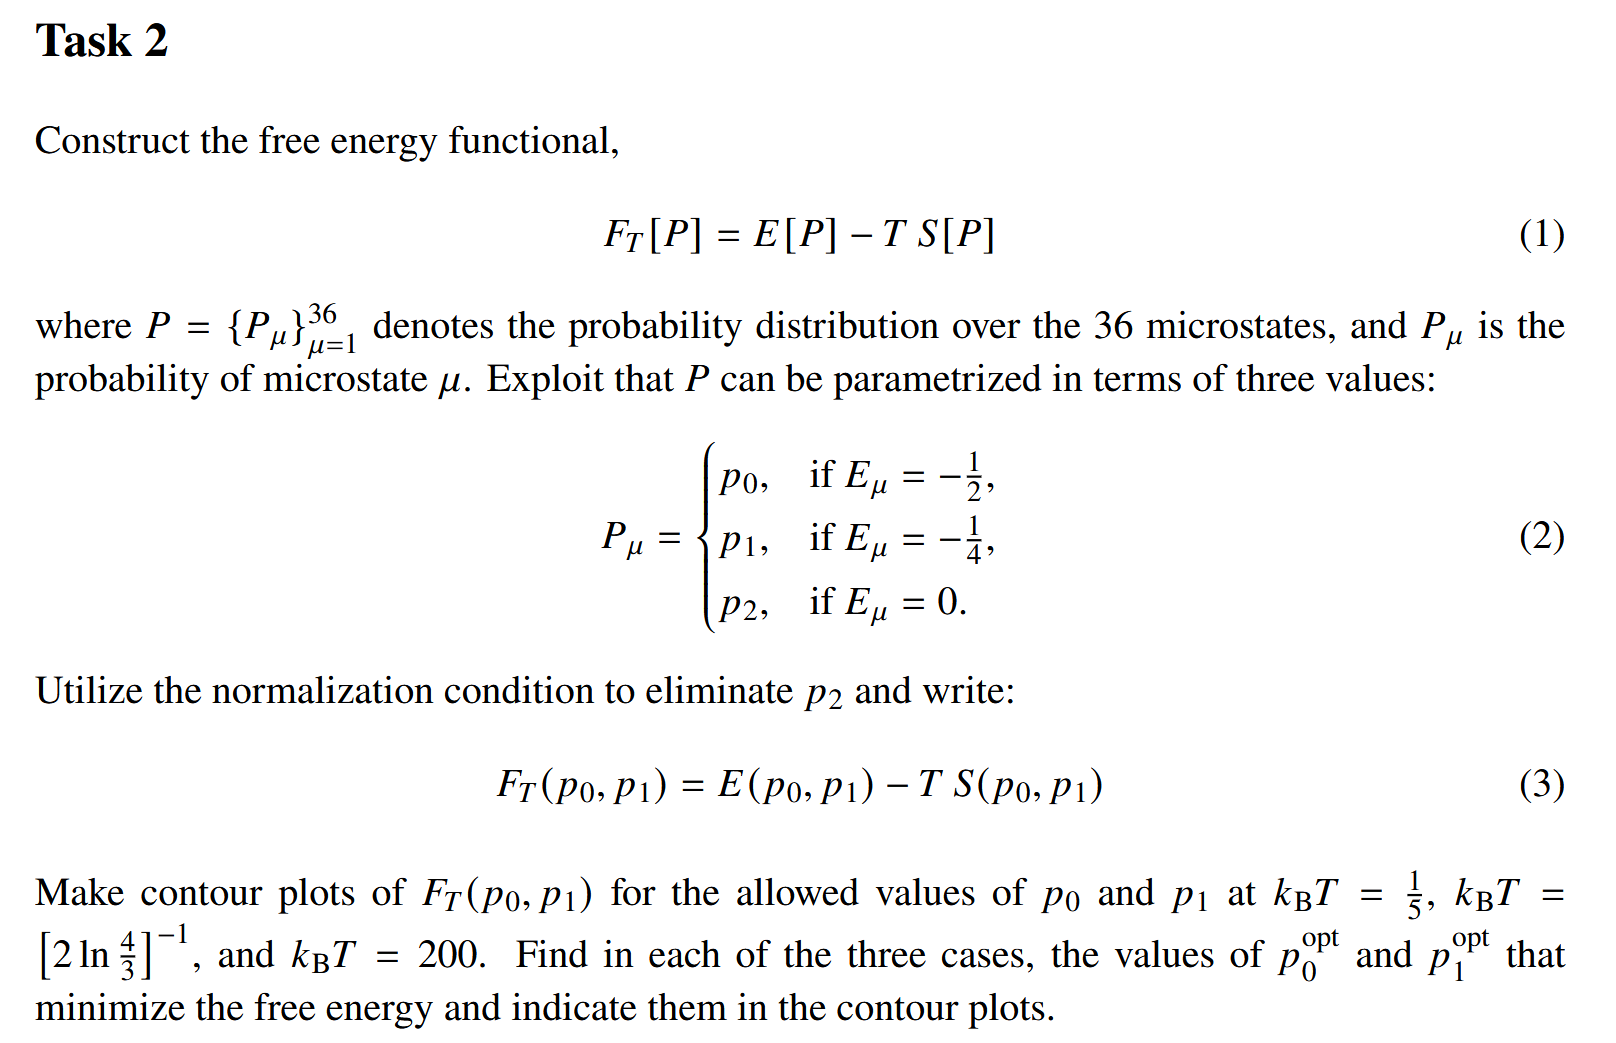

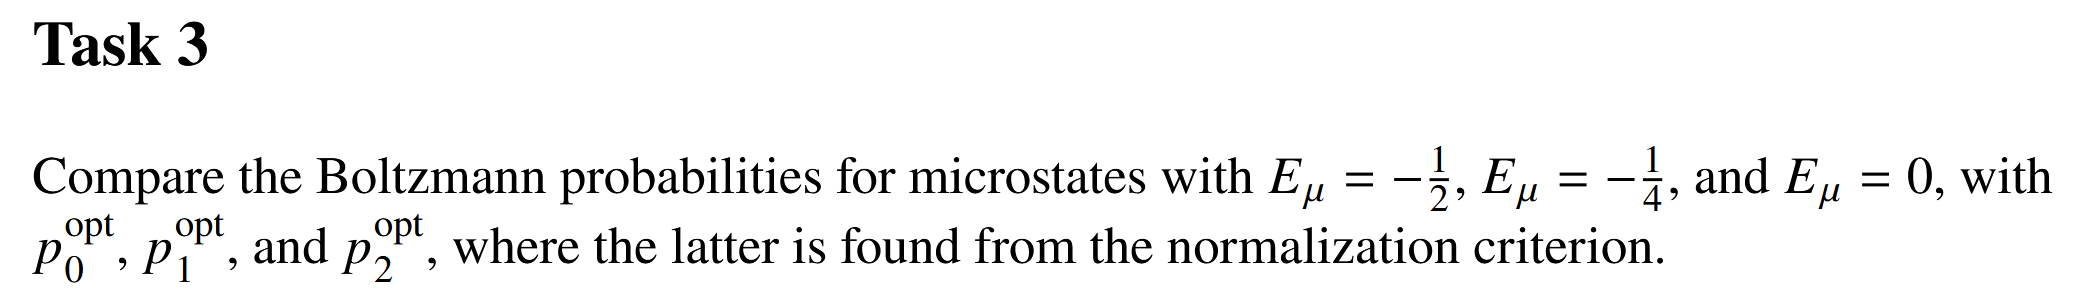

In [34]:
import numpy as np
import matplotlib.pyplot as plt 

class FreeEnergy:
    def __init__(self, kT, p0, p1):
        self.kT = kT
        self.p0 = p0
        self.p1 = p1

        # p2 using normalization
        self.p2 = (1 - 12 * self.p0 - 8 * self.p1) / 16.0

    @property
    def E(self):
        '''sum(E_ip_1n_i)'''
        return 12*(-0.5)*self.p0 + 8*(-0.25)*self.p1

    @property
    def S(self):
        ''' -sum(n_i * p_i * ln(p_i)) '''
        return -(12 * self.p0 * np.log(self.p0) + 
                 8  * self.p1 * np.log(self.p1) + 
                 16 * self.p2 * np.log(self.p2))
    @property
    def F(self):
        return self.E - self.kT * self.S
    

    def plot(self, ax, title):
        F_valid = np.where(self.p2 >= 0, self.F, np.nan)

        # Find the minimum directly from the valid grid
        min_index = np.nanargmin(F_valid)
        p0_opt = self.p0.flat[min_index]
        p1_opt = self.p1.flat[min_index]

        # Draw the contour plot
        cp = ax.contourf(self.p0, self.p1, F_valid, levels=20, cmap='viridis')
        plt.colorbar(cp, ax=ax, label='Free Energy')

        # Draw the boundary line (12*p0 + 8*p1 = 1)
        p0_line = np.linspace(0, 1/12, 100)
        p1_line = (1 - 12 * p0_line) / 8.0
        ax.plot(p0_line, p1_line, 'k--', linewidth=2)

        # Mark the optimum point
        ax.plot(p0_opt, p1_opt, 'x', color='coral', markersize=8, markeredgewidth=2)
        ax.set_title(f"{title}\n$p_0^{{opt}}$={p0_opt:.3f}, $p_1^{{opt}}$={p1_opt:.3f}")
        ax.set_xlabel('$p_0$')
        ax.set_ylabel('$p_1$')
        ax.set_xlim(0, 0.10)
        ax.set_ylim(0, 0.15)

        return p0_opt, p1_opt


C:\Users\Moth\AppData\Local\Temp\ipykernel_1832\1007190278.py:23: RuntimeWarning: divide by zero encountered in log
  16 * self.p2 * np.log(self.p2))
C:\Users\Moth\AppData\Local\Temp\ipykernel_1832\1007190278.py:23: RuntimeWarning: invalid value encountered in log
  16 * self.p2 * np.log(self.p2))
C:\Users\Moth\AppData\Local\Temp\ipykernel_1832\1007190278.py:23: RuntimeWarning: invalid value encountered in multiply
  16 * self.p2 * np.log(self.p2))



 --- For k_bT = 0.2 --- 
Minimization: p0 = 0.064, p1 = 0.019, p2 = 0.005
Boltzmann:    p0 = 0.064, p1 = 0.018, p2 = 0.005

 --- For k_bT = 1.738029748391104 --- 
Minimization: p0 = 0.033, p1 = 0.027, p2 = 0.024
Boltzmann:    p0 = 0.032, p1 = 0.028, p2 = 0.024

 --- For k_bT = 200 --- 
Minimization: p0 = 0.028, p1 = 0.027, p2 = 0.028
Boltzmann:    p0 = 0.028, p1 = 0.028, p2 = 0.028


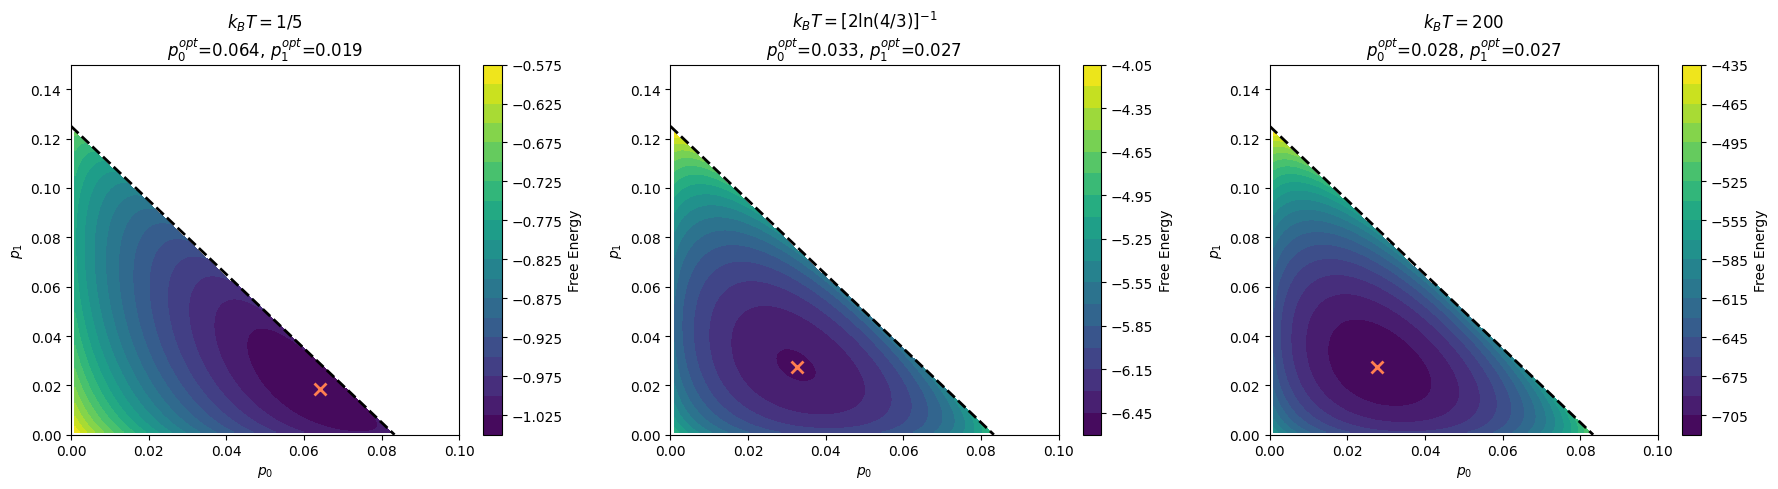

: 

In [ ]:
# Create the common 2D probability grid
p0_vals = np.linspace(0.001, 1/12, 100)
p1_vals = np.linspace(0.001, 1/8, 100)
P0, P1 = np.meshgrid(p0_vals, p1_vals)

temperatures = {
    r"$k_B T = 1/5$": 1/5,
    r"$k_B T = [2 \ln(4/3)]^{-1}$": 1 / (2 * np.log(4/3)),
    r"$k_B T = 200$": 200
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, kT) in zip(axes, temperatures.items()):
    fe_system = FreeEnergy(kT, P0, P1)    
    p0, p1 = fe_system.plot(ax, title)
    print('\n' + f' --- For k_bT = {kT} --- ')
    print(f'Minimization: p0 = {p0:.3f}, p1 = {p1:.3f}, p2 = {(1 - 12 * p0 - 8 * p1) / 16.0:.3f}')

    Z = 12 * np.exp(0.5 / kT) + 8 * np.exp(0.25 / kT) + 16 * np.exp(0.0 / kT)
    p0b = np.exp(0.5/kT) / Z
    p1b = np.exp(0.25/kT) / Z
    p2b = 1.0 / Z
    print(f'Boltzmann:    p0 = {p0b:.3f}, p1 = {p1b:.3f}, p2 = {p2b:.3f}')

plt.tight_layout()
plt.show()

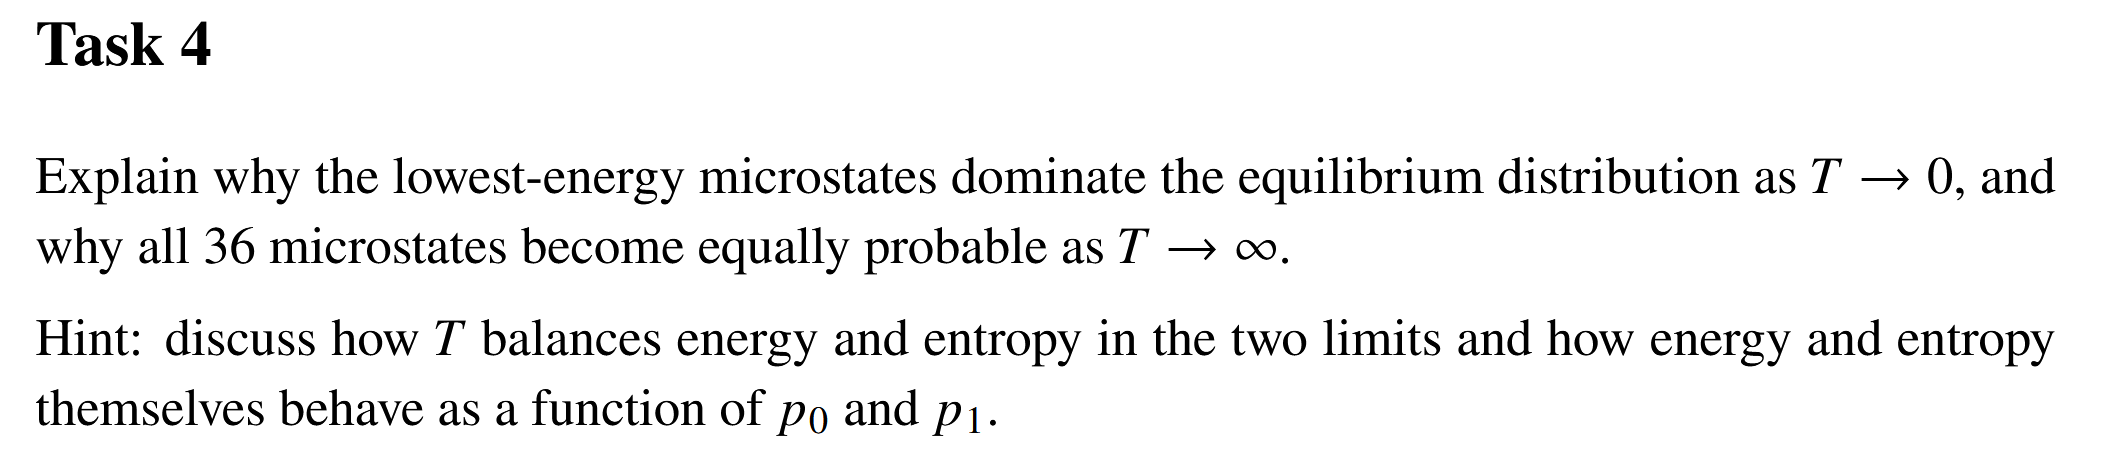

Naturen vil altid forsøge at minimere den samlede fri energi ($F_T$). Temperaturen ($T$) fungerer her som en skaleringsfaktor, der bestemmer, om systemet prioriterer at minimere energien eller maksimere entropien (uordenen).

**Når $T \to 0$ (Lav temperatur):**
* Ved meget lave temperaturer bliver bidraget fra entropien ($T \cdot S$) forsvindende lille. Ligningen reduceres effektivt til $F_T \approx E$.
* For at minimere $F_T$ er systemet tvunget til at minimere sin indre energi.
* Derfor vil systemet udelukkende besætte de mikrotilstande, der har den laveste energi (domineret af $p_0$). Den termiske energi er ikke høj nok til, at systemet kan overvinde energiforskellen og besøge de højere energiniveauer.


**Når $T \to \infty$ (Høj temperatur):**
* Ved meget høje temperaturer bliver entropi-leddet ($-T \cdot S$) uendeligt stort og dominerer fuldstændig over systemets indre energi ($E$). De små forskelle mellem energiniveauerne ($-1/2$, $-1/4$, $0$) bliver ubetydelige.
* For at minimere $F_T$ i denne grænse, skal systemet i stedet maksimere sin entropi ($S$).
* Entropien er maksimeret, når der er fuldstændig maksimal uorden. Dette opnås kun, når systemet er fuldt ud tilfældigt, hvilket betyder, at **alle 36 mikrotilstande bliver lige sandsynlige** (hver med sandsynligheden $1/36$). Systemet bevæger sig frit mellem alle tilstande uden at blive bremset af energibarrierer.